## piirteiden irrottaminen

data ladataan harjoitus ja testi aineistoihin. data muokataan VGG16 käyttömäksi muodoksi. data survotaan mallin läpi mutta koska malli ei ole kokonainen lopputuloksena saadaan kuvien piirteitä ilmaiseva vektori. tämä vektori syötetään FCC mallille joka opetetaan ennustamaan luokkia VGG16 ulos sylkemien vektorien perusteella.

In [11]:
import keras
import numpy as np
from keras.applications import VGG16
from keras import layers

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = keras.applications.vgg16.preprocess_input(
    x_train.astype("float32")
)

x_test = keras.applications.vgg16.preprocess_input(
    x_test.astype("float32")
)

base = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(32, 32, 3)
)

base.trainable = False

train_features = base.predict(
    x_train,
    batch_size=64
)

test_features = base.predict(
    x_test,
    batch_size=64
)

print(train_features.shape, test_features.shape)

782/782 ━━━━━━━━━━━━━━━━━━━━ 63s 81ms/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 84ms/step
(50000, 1, 1, 512) (10000, 1, 1, 512)


## FCC osuus

flatten muuttaa vgg16 saadun feature mapin (1,1,512) vektoriksi. dense kerros 206 neuronilla oppii ennustamaan vektorista. batch normalization vakauttaa koulutusta. dropout vähentää ylioppimista. lopuksi dense luokittelee 10 luokkaan.

In [51]:
inputs = keras.Input(shape=train_features.shape[1:])

x = layers.Flatten()(inputs)

x = layers.Dense(206)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(10, activation="softmax")(x)

model = keras.Model(inputs, outputs)


model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


history = model.fit(
    train_features,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3898 - loss: 1.7832 - val_accuracy: 0.5588 - val_loss: 1.2730
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5392 - loss: 1.3357 - val_accuracy: 0.6016 - val_loss: 1.1415
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5775 - loss: 1.2211 - val_accuracy: 0.6199 - val_loss: 1.0798
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6002 - loss: 1.1506 - val_accuracy: 0.6317 - val_loss: 1.0431
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6131 - loss: 1.1072 - val_accuracy: 0.6400 - val_loss: 1.0182
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6280 - loss: 1.0671 - val_accuracy: 0.6500 - val_loss: 0.9986
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6379 - loss: 1.0405 - val_accuracy: 0.6544 - val_loss: 0.9840
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6462 - loss: 1.0151 - val_accuracy: 0.

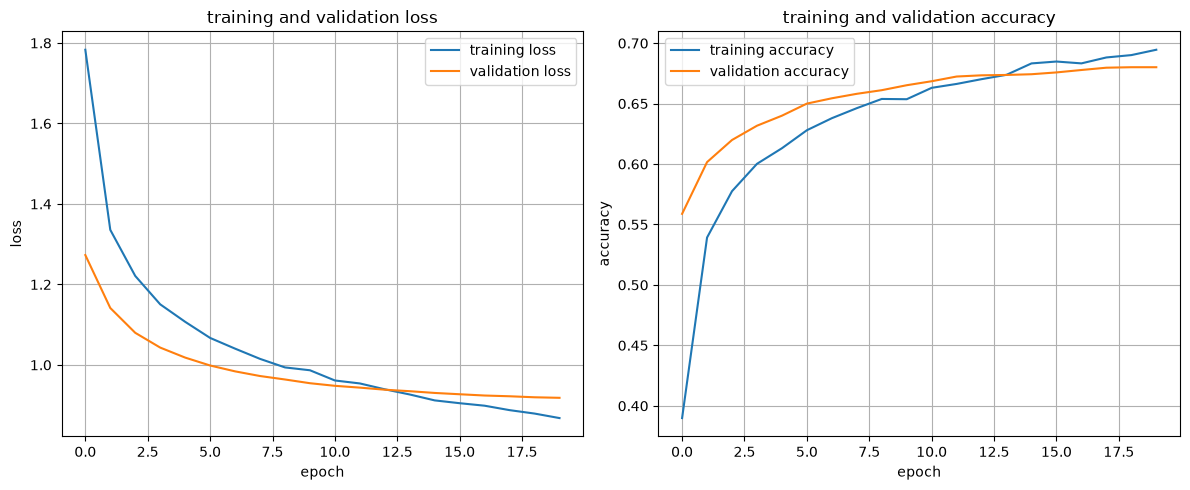

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.title("training and validation loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="training accuracy")
plt.plot(history.history["val_accuracy"], label="validation accuracy")
plt.title("training and validation accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [55]:
test_loss, test_accuracy = model.evaluate(
    test_features,
    y_test
)

print(test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 822us/step - accuracy: 0.6786 - loss: 0.9260
0.678600013256073
